# Telecom site-down analysis — corrected Model2

This is a corrected copy of `Model2(1).ipynb`. Run from the extracted project folder. Original files are unchanged.

**Scope:** classify the recorded `is_site_down` status in the supplied synthetic dataset. This is **retrospective**, not a forecast. `repair_time` and assigned `techs` may only be known after an incident. Do not use these results for advance failure warnings. No future horizon or independently collected validation data is available.

Existing model families and hyperparameters are retained: Logistic Regression, ANN, Decision Tree, and both existing Random Forest configurations. No hyperparameter search. The final balanced RF is retained for inference because it was the original deployment configuration, not because it is necessarily best.

Corrections: portable paths; consistent names; fold-only feature selection, imputation, one-hot encoding and scaling; tower-disjoint 12-fold evaluation; one fit per model/fold; pooled out-of-fold reports; full-data inference refit; explicit input validation. One-hot encoding changes the feature representation, hence corrected metrics need not match old results. Original p-value selection is retained but moved inside folds; it is exploratory, unadjusted for multiple comparisons, and not causal evidence.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
os.environ['TF_NUM_INTRAOP_THREADS']='2'
os.environ['TF_NUM_INTEROP_THREADS']='2'
os.environ['OMP_NUM_THREADS']='2'
from pathlib import Path
import json, hashlib, platform, importlib.metadata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from core import CANDIDATES, CATEGORICAL, normalize, preprocessing
warnings.filterwarnings('error', category=ConvergenceWarning)
ROOT=Path.cwd()
DATA=ROOT/'data'/'simulated_year7.xlsx'
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
if not DATA.exists():
    raise FileNotFoundError(f'Open this notebook from the extracted project folder. Missing: {DATA}')
print('Python:',platform.python_version(),'TensorFlow:',tf.__version__)

Python: 3.12.14 TensorFlow: 2.21.0


## 1. Load and validate the supplied data
No records are silently dropped. Tower IDs are grouping identifiers, never predictors. `Days` duplicates month/day; `affected_service_count` is excluded as in the original notebook.

In [2]:
df=pd.read_excel(DATA)
required=set(CANDIDATES+['tower_id','is_site_down'])
assert required.issubset(df.columns), f'Missing columns: {required-set(df.columns)}'
assert df['tower_id'].notna().all(), 'Missing tower IDs'
assert df['is_site_down'].notna().all() and set(df['is_site_down'].unique())=={0,1}
assert not df.duplicated().any(), 'Exact duplicates require review before evaluation'
X=normalize(df)
y=df['is_site_down'].astype(int).to_numpy()
groups=df['tower_id'].to_numpy()
print('Shape:',df.shape)
print('Missing values:',df.isna().sum().to_dict())
print('Exact duplicates:',int(df.duplicated().sum()))
print('Unique towers:',df.tower_id.nunique())
print('Repeated tower/day rows:',int(df.duplicated(['tower_id','Month','Day']).sum()))
print('Class counts:',df.is_site_down.value_counts().to_dict())
print('Majority-class reference accuracy:',float((y==0).mean()))
display(df.head())
display(df.groupby('is_site_down')['repair_time'].describe())
# Normalized data retains all original columns for display.
clean=df.copy()
clean[CANDIDATES]=X
clean.to_csv(ROOT/'data'/'records.csv.gz',index=False,compression='gzip')

Shape: (198487, 12)
Missing values: {'Region': 0, 'Depot': 0, 'tower_id': 0, 'Network_type': 0, 'Month': 0, 'Day': 0, 'affected_service_count': 0, 'equipment_vendor': 0, 'techs': 0, 'repair_time': 0, 'is_site_down': 0, 'Days': 0}
Exact duplicates: 0
Unique towers: 6773
Repeated tower/day rows: 13929
Class counts: {0: 138842, 1: 59645}
Majority-class reference accuracy: 0.6995017305919279


,Region,Depot,tower_id,Network_type,Month,Day,affected_service_count,equipment_vendor,techs,repair_time,is_site_down,Days
0,western,Malabe,5622,IP,january,1,3,Huawei,312,4.311390,0,january 1
1,southern,Hambantota,4007,Radio Access Network,january,1,2,Ericson,223,3.815089,0,january 1
2,western,Hanwella,5124,IP,january,1,3,Huawei,286,1.030952,0,january 1
3,western,Mahabage,5393,microwave,january,1,6,Huawei,302,7.437849,1,january 1
4,western,Kesbewa,5352,IP,january,1,4,Cisco,297,3.947751,0,january 1


,count,mean,std,min,25%,50%,75%,max
is_site_down,,,,,,,,
0,138842.0,2.845070,0.870573,0.663970,2.222701,2.719518,3.329971,11.652446
1,59645.0,3.869118,1.527117,0.834748,2.722256,3.616103,4.747900,14.829273


## 2. Group-aware evaluation
Each tower occurs in only one test fold. All models use the same folds. This estimates transfer to held-out towers in the same synthetic period, **not future-period performance**. Repeated tower/day rows are not necessarily duplicates: no event ID is supplied, so they are retained within their tower group. Correlated depots/technicians may span folds. Fold standard deviations are descriptive, not confidence intervals.

In [3]:
splitter=StratifiedGroupKFold(n_splits=12,shuffle=True,random_state=42)
splits=list(splitter.split(X,y,groups))
coverage=np.zeros(len(y),dtype=int)
for train,test in splits:
    assert not set(groups[train]).intersection(groups[test])
    assert len(np.unique(y[train]))==2 and len(np.unique(y[test]))==2
    coverage[test]+=1
assert (coverage==1).all()
print('Verified 12 tower-disjoint folds; every row is held out exactly once.')

def estimators():
    return {
      'Logistic Regression':LogisticRegression(),
      'Decision Tree':DecisionTreeClassifier(max_depth=4,min_samples_split=20,min_samples_leaf=10,max_leaf_nodes=10,max_features=.5,ccp_alpha=.01,random_state=42),
      'Random Forest (20)':RandomForestClassifier(n_estimators=20,max_depth=12,random_state=42,n_jobs=2),
      'Random Forest (balanced 200)':RandomForestClassifier(n_estimators=200,max_depth=12,random_state=42,class_weight='balanced',n_jobs=2)}
names=list(estimators())+['ANN']
oof={name:np.full(len(y),np.nan) for name in names}
fold_id=np.zeros(len(y),dtype=int)
fold_metrics=[]
histories=[]
selections=[]

def tf_dataset(a,b,training=False,seed=42):
    ds=tf.data.Dataset.from_tensor_slices((a,b))
    if training: ds=ds.shuffle(len(a),seed=seed,reshuffle_each_iteration=True)
    options=tf.data.Options()
    options.threading.private_threadpool_size=1
    return ds.batch(32).with_options(options)


Verified 12 tower-disjoint folds; every row is held out exactly once.


## 3. Train the existing configurations
This cell is expensive. ANN architecture, dropout, five epochs, batch size 32, Adam and binary cross-entropy are unchanged. Outer-fold loss is retained solely as a diagnostic; there is no early stopping, model selection or tuning using it. All 12 histories are retained rather than showing the final fold as the overall training curve.

In [4]:
for fold,(train,test) in enumerate(splits,1):
    print(f'Fold {fold}/12 starting',flush=True)
    pre=preprocessing()
    a=pre.fit_transform(X.iloc[train],y[train])
    b=pre.transform(X.iloc[test])
    selections.append({'fold':fold,'selected':pre.named_steps['select'].selected_,
                       'p_values':pre.named_steps['select'].p_values_})
    fold_id[test]=fold
    for name,model in estimators().items():
        model.fit(a,y[train])
        p=model.predict_proba(b)[:,1]
        oof[name][test]=p
        fold_metrics.append({'model':name,'fold':fold,'n_test':len(test),'accuracy':accuracy_score(y[test],p>.5)})
        print(name,round(fold_metrics[-1]['accuracy'],4),flush=True)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42+fold)
    ann=tf.keras.Sequential([
       tf.keras.layers.Input(shape=(a.shape[1],)),
       tf.keras.layers.Dense(8,activation='relu'),tf.keras.layers.Dropout(.5),
       tf.keras.layers.Dense(4,activation='relu'),tf.keras.layers.Dropout(.5),
       tf.keras.layers.Dense(1,activation='sigmoid')])
    ann.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
    ad=a.toarray().astype('float32') if hasattr(a,'toarray') else a.astype('float32')
    bd=b.toarray().astype('float32') if hasattr(b,'toarray') else b.astype('float32')
    h=ann.fit(tf_dataset(ad,y[train],True,42+fold),epochs=5,
              validation_data=tf_dataset(bd,y[test]),verbose=0)
    histories.append({'fold':fold,**h.history})
    p=np.concatenate([ann(bd[i:i+2048],training=False).numpy().ravel() for i in range(0,len(bd),2048)])
    oof['ANN'][test]=p
    fold_metrics.append({'model':'ANN','fold':fold,'n_test':len(test),'accuracy':accuracy_score(y[test],p>.5)})
    print('ANN',round(fold_metrics[-1]['accuracy'],4),flush=True)
    del ad,bd,a,b,ann
assert all(np.isfinite(p).all() for p in oof.values())
print('All 60 model/fold fits completed.')

Fold 1/12 starting
Logistic Regression 0.7532
Decision Tree 0.7338
Random Forest (20) 0.7096
Random Forest (balanced 200) 0.7282
ANN 0.6996
Fold 2/12 starting
Logistic Regression 0.7577
Decision Tree 0.7405
Random Forest (20) 0.7163
Random Forest (balanced 200) 0.7194
ANN 0.7428
Fold 3/12 starting
Logistic Regression 0.7588
Decision Tree 0.7431
Random Forest (20) 0.7053
Random Forest (balanced 200) 0.731
ANN 0.6996
Fold 4/12 starting
Logistic Regression 0.7586
Decision Tree 0.7393
Random Forest (20) 0.7045
Random Forest (balanced 200) 0.7297
ANN 0.7388
Fold 5/12 starting
Logistic Regression 0.7565
Decision Tree 0.7386
Random Forest (20) 0.7022
Random Forest (balanced 200) 0.7324
ANN 0.7506
Fold 6/12 starting
Logistic Regression 0.7623
Decision Tree 0.7448
Random Forest (20) 0.7152
Random Forest (balanced 200) 0.739
ANN 0.7557
Fold 7/12 starting
Logistic Regression 0.7573
Decision Tree 0.7407
Random Forest (20) 0.7216
Random Forest (balanced 200) 0.7363
ANN 0.755
Fold 8/12 starting
Logi

/tmp/tower-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/tmp/tower-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/tmp/tower-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/tmp/to

## 4. Honest aggregate results
Reports and confusion matrices use all out-of-fold predictions. Mean fold accuracy is also shown separately because fold sizes differ. Positive-class precision/recall/F1 use `is_site_down=1`. Accuracy alone can hide poor positive-class recall.


 Logistic Regression
              precision    recall  f1-score   support

           0       0.77      0.94      0.84    138842
           1       0.71      0.33      0.45     59645

    accuracy                           0.76    198487
   macro avg       0.74      0.64      0.65    198487
weighted avg       0.75      0.76      0.73    198487

Confusion matrix [actual rows, predicted columns; 0 then 1]: [[130635, 8207], [39828, 19817]]

 Decision Tree
              precision    recall  f1-score   support

           0       0.75      0.94      0.84    138842
           1       0.66      0.28      0.39     59645

    accuracy                           0.74    198487
   macro avg       0.71      0.61      0.61    198487
weighted avg       0.73      0.74      0.70    198487

Confusion matrix [actual rows, predicted columns; 0 then 1]: [[130497, 8345], [43125, 16520]]

 Random Forest (20)
              precision    recall  f1-score   support

           0       0.71      0.99      0.83 

,model,accuracy,precision,recall,f1,mean_fold_accuracy,std_fold_accuracy
0,Logistic Regression,0.757994,0.707144,0.332249,0.452087,0.757994,0.002912
1,Decision Tree,0.740688,0.664388,0.276972,0.390960,0.740688,0.003282
2,Random Forest (20),0.712974,0.763604,0.064934,0.119690,0.712973,0.010711
3,Random Forest (balanced 200),0.732189,0.563575,0.482136,0.519684,0.732188,0.005417
4,ANN,0.736587,0.803096,0.163501,0.271689,0.736585,0.022901


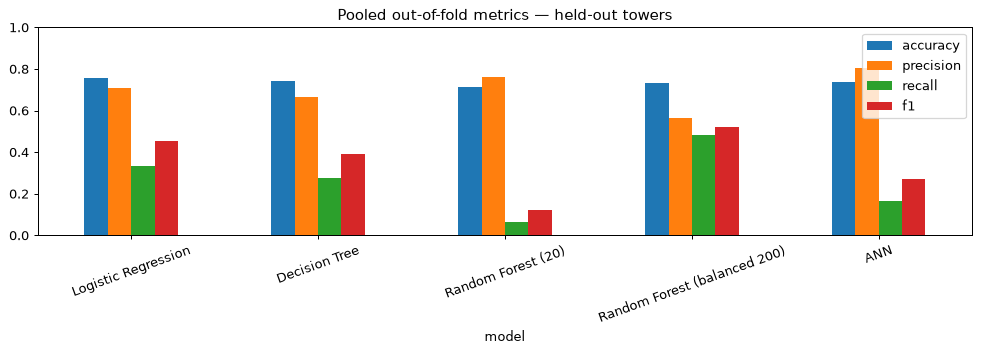

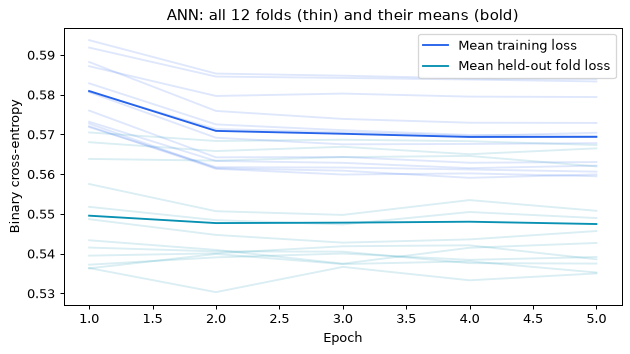

In [5]:
fold_table=pd.DataFrame(fold_metrics)
rows=[]
reports={}
confusions={}
for name,p in oof.items():
    pred=(p>.5).astype(int)
    acc=fold_table.loc[fold_table.model==name,'accuracy']
    rows.append({'model':name,'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),
                 'recall':recall_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0),
                 'mean_fold_accuracy':acc.mean(),'std_fold_accuracy':acc.std(ddof=1)})
    reports[name]=classification_report(y,pred,output_dict=True,zero_division=0)
    confusions[name]=confusion_matrix(y,pred,labels=[0,1]).tolist()
metrics=pd.DataFrame(rows)
display(metrics)
for name in names:
    print('\n',name)
    print(classification_report(y,oof[name]>.5,zero_division=0))
    print('Confusion matrix [actual rows, predicted columns; 0 then 1]:',confusions[name])
metrics.set_index('model')[['accuracy','precision','recall','f1']].plot.bar(figsize=(11,4),ylim=(0,1),rot=20)
plt.title('Pooled out-of-fold metrics — held-out towers');plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for h in histories:
    ax.plot(range(1,6),h['loss'],color='#2563eb',alpha=.15)
    ax.plot(range(1,6),h['val_loss'],color='#0891b2',alpha=.15)
ax.plot(range(1,6),np.mean([h['loss'] for h in histories],axis=0),color='#2563eb',label='Mean training loss')
ax.plot(range(1,6),np.mean([h['val_loss'] for h in histories],axis=0),color='#0891b2',label='Mean held-out fold loss')
ax.set(xlabel='Epoch',ylabel='Binary cross-entropy',title='ANN: all 12 folds (thin) and their means (bold)')
ax.legend();plt.show()
metrics.to_csv(OUT/'metrics.csv',index=False)
fold_table.to_csv(OUT/'fold_metrics.csv',index=False)
pd.DataFrame({'row_id':np.arange(len(y)),'tower_id':groups,'fold':fold_id,'actual':y,**oof}).to_csv(OUT/'oof_predictions.csv.gz',index=False,compression='gzip')
for filename,value in [('reports.json',reports),('confusions.json',confusions),('ann_histories.json',histories),('fold_selections.json',selections)]:
    (OUT/filename).write_text(json.dumps(value,indent=2),encoding='utf-8')

## 5. Refit the existing deployment configuration
The balanced 200-tree RF is fitted on all rows with its own complete preprocessing pipeline. Its training accuracy is not substituted for OOF metrics. Scores are uncalibrated, especially with class weighting; Low/Medium/High are the original illustrative score bands (0.4/0.7), not validated operational risk levels. The app loads this pipeline and never retrains on interaction.

In [6]:
final=Pipeline([('preprocess',preprocessing()),('model',estimators()['Random Forest (balanced 200)'])])
final.fit(X,y)
joblib.dump(final,OUT/'site_status_pipeline.joblib',compress=3)
versions={p:importlib.metadata.version(p) for p in ['pandas','numpy','scikit-learn','tensorflow-cpu','streamlit','plotly','joblib','scipy']}
metadata={'rows':len(df),'columns':list(df.columns),'towers':int(df.tower_id.nunique()),
 'class_counts':{str(k):int(v) for k,v in df.is_site_down.value_counts().items()},
 'missing_cells':int(df.isna().sum().sum()),'exact_duplicates':int(df.duplicated().sum()),
 'repeated_tower_days':int(df.duplicated(['tower_id','Month','Day']).sum()),
 'dataset_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest(),'versions':versions,
 'python':platform.python_version(),'candidates':CANDIDATES,
 'final_selected':final.named_steps['preprocess'].named_steps['select'].selected_,
 'categories':{col:sorted(X[col].dropna().unique().tolist()) for col in CATEGORICAL},
 'region_depot_tech':X[['Region','Depot','techs']].drop_duplicates().values.tolist(),
 'repair_time_range':[float(X.repair_time.min()),float(X.repair_time.max())],
 'scope':'Retrospective recorded site-down status; synthetic data; not future failure forecasting.',
 'evaluation':'12-fold StratifiedGroupKFold by tower_id; OOF predictions; threshold > 0.5',
 'deployment_model':'Random Forest (balanced 200)'}
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
from core import score_batch
sample=df.head(10)[CANDIDATES]
reloaded=joblib.load(OUT/'site_status_pipeline.joblib')
np.testing.assert_allclose(final.predict_proba(X.head(10)),reloaded.predict_proba(X.head(10)))
display(score_batch(reloaded,sample,metadata))
sample.to_csv(ROOT/'data'/'example_batch.csv',index=False)
print('Saved verified OOF results and a full-data inference pipeline.')

Saved verified OOF results and a full-data inference pipeline.


,Region,Depot,Network_type,Month,equipment_vendor,Day,techs,repair_time,site_down_score,predicted_status,score_band
0,western,Malabe,IP,january,Huawei,1,312,4.311390,0.607196,1,Medium
1,southern,Hambantota,Radio Access Network,january,Ericson,1,223,3.815089,0.473970,0,Medium
2,western,Hanwella,IP,january,Huawei,1,286,1.030952,0.428081,0,Medium
3,western,Mahabage,microwave,january,Huawei,1,302,7.437849,0.629915,1,Medium
4,western,Kesbewa,IP,january,Cisco,1,297,3.947751,0.576314,1,Medium
5,central,Ruwanwella,IP,january,Huawei,1,88,3.898208,0.594057,1,Medium
6,western,Malabe,microwave,january,Huawei,1,314,2.227348,0.444392,0,Medium
7,eastern,Batticaloa,IP,january,Ericson,1,106,3.084467,0.446582,0,Medium
8,western,Dehiwala,IP,january,Huawei,1,275,4.300399,0.607096,1,Medium
9,southern,Kalutara,IP,january,Huawei,1,240,3.741985,0.459438,0,Medium


## Limitations and running the dashboard

- This synthetic file has no verified generation code, event timestamps, future labels or external validation set. No real-world reliability claim is supported.
- `repair_time` and `techs` are allowed only for retrospective classification. A prospective task requires a new target definition and pre-event data, outside this correction scope.
- The historical exploratory choices cannot be independently validated using this same dataset; fold-only association selection removes direct test-label access during this run, but does not create an untouched external test set.
- One-hot encoding may weaken the aggressively constrained original Decision Tree. Its hyperparameters are intentionally unchanged; no tuning was performed.
- Fold test-loss curves are descriptive. Do not select epochs by inspecting them and then claim the same folds are an untouched test set.
- No in-notebook Streamlit launch: in Anaconda Prompt, run `python -m streamlit run app.py`. See `README.md` for full setup. See `REVIEW_SI.md` for corrections and original cell references.
